In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
# use Seaborn styles
sns.set() 

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

import os
emergency = pd.read_csv("../input/911.csv")
emergency.head()
# Any results you write to the current directory are saved as output.

,lat,lng,desc,zip,title,timeStamp,twp,addr,e
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:10:52,NEW HANOVER,REINDEER CT & DEAD END,1
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:29:21,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 14:39:21,NORRISTOWN,HAWS AVE,1
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 16:47:36,NORRISTOWN,AIRY ST & SWEDE ST,1
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 16:56:52,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1


In [2]:
total = emergency.isnull().sum().sort_values(ascending=False)
total
#Two columns have null values - zip and twp

zip          39590
twp            115
e                0
addr             0
timeStamp        0
title            0
desc             0
lng              0
lat              0
dtype: int64

**Q1 - Calculate the percentage of missing values column wise**

In [3]:
percent = (emergency.isnull().sum()/emergency.isnull().count()).sort_values(ascending = False)
#print(percent)
pd1 = pd.concat([total,percent],axis =1 ,keys=['Total','Percent'])
pd2 = pd1[pd1['Total']>0]
print(pd2)
#zip has 0.12 percent of null values
#twp has very small percent of null values

     Total   Percent
zip  39590  0.121284
twp    115  0.000352


**Q2 - Top 10 titles on the basis of the count of 911 emergency calls in a table and displayed in a pie chart**

                                 e
title                             
Traffic: VEHICLE ACCIDENT -  76179
Traffic: DISABLED VEHICLE -  23957
Fire: FIRE ALARM             18436
EMS: RESPIRATORY EMERGENCY   16602
EMS: FALL VICTIM             16438
EMS: CARDIAC EMERGENCY       16100
EMS: VEHICLE ACCIDENT        12976
Traffic: ROAD OBSTRUCTION -  10668
EMS: SUBJECT IN PAIN          9149
EMS: HEAD INJURY              8491


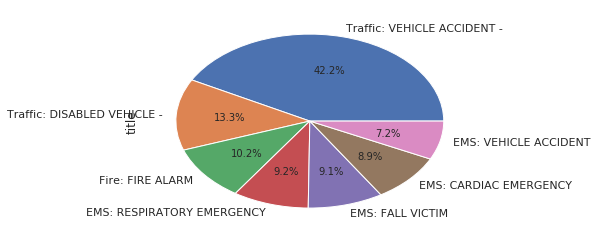

In [4]:
#to reset the index
#emergency.reset_index(inplace=True)
title1 = emergency.pivot_table(values = 'e',index=['title'],aggfunc='count')

#display the top 10 title
print(title1.sort_values('e',ascending=False).head(10))

#groupby on the basis of title and then plot a pie chart
emergency.groupby(['title'])['title'].size().sort_values(ascending=False).head(7).plot(kind='pie',autopct='%1.1f%%')

#'Traffic: VEHICLE ACCIDENT' title has the highest 911 calls

**Top 5 Traffic emergency titles**

In [5]:
#Extract only the titles with 'Traffic' and display the top 5 titles
print(title1[title1.index.str.contains('^Traffic')].sort_values('e',ascending=False).head(5))

                                          e
title                                      
Traffic: VEHICLE ACCIDENT -           76179
Traffic: DISABLED VEHICLE -           23957
Traffic: ROAD OBSTRUCTION -           10668
Traffic: HAZARDOUS ROAD CONDITIONS -   3222
Traffic: VEHICLE FIRE -                1739


**Seperate the type of the title and add it in a new column - 'type'**

In [6]:
#Extracting the type from the titles and storing it in a new column
emergency['type'] = emergency["title"].apply(lambda x: x.split(':')[0])
emergency.head()

,lat,lng,desc,zip,title,timeStamp,twp,addr,e,type
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:10:52,NEW HANOVER,REINDEER CT & DEAD END,1,EMS
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:29:21,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1,EMS
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 14:39:21,NORRISTOWN,HAWS AVE,1,Fire
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 16:47:36,NORRISTOWN,AIRY ST & SWEDE ST,1,EMS
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 16:56:52,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1,EMS


**Q3  Bar plot and pie plot of the type of emergency
Bar plot - showing the count of the different types
Pie plot - Showing the perecentage of the different types****        

              e
type           
EMS      161441
Traffic  116065
Fire      48919


Text(0,0.5,'count')

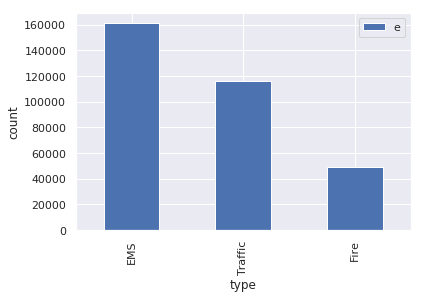

In [7]:
#emergency.reset_index(inplace=True)
title2 = emergency.pivot_table(values = 'e',index=['type'],aggfunc='count').sort_values('e',ascending=False)
print(title2)
title2.plot(kind='bar')
plt.ylabel("count")

#EMS type has the highest count of 911 calls although the 
#'Traffic: VEHICLE ACCIDENT' title has the highest count of 911 calls

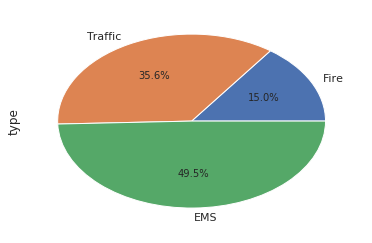

In [8]:
#pie-chart displaying the percent of different types
emergency.groupby(['type'])['type'].size().sort_values(ascending=True).plot(kind='pie',autopct='%1.1f%%')

**Q4 - Showing the top titles for each types using pivot table and displaying it in a bar chart**

                                            e
type    title                                
EMS     EMS: CARDIAC EMERGENCY          16100
        EMS: FALL VICTIM                16438
        EMS: GENERAL WEAKNESS            5339
        EMS: HEAD INJURY                 8491
        EMS: RESPIRATORY EMERGENCY      16602
        EMS: SEIZURES                    5371
        EMS: SUBJECT IN PAIN             9149
        EMS: SYNCOPAL EPISODE            5554
        EMS: UNKNOWN MEDICAL EMERGENCY   5670
        EMS: VEHICLE ACCIDENT           12976
Fire    Fire: FIRE ALARM                18436
        Fire: VEHICLE ACCIDENT           5541
Traffic Traffic: DISABLED VEHICLE -     23957
        Traffic: ROAD OBSTRUCTION -     10668
        Traffic: VEHICLE ACCIDENT -     76179


Text(0,0.5,'count')

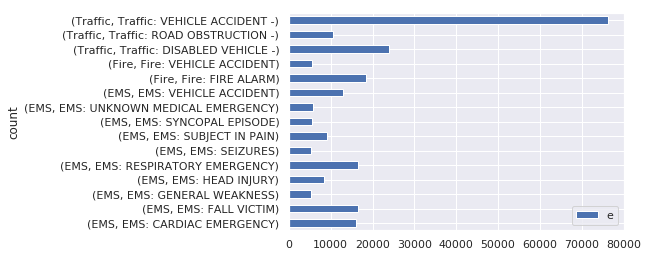

In [9]:
#emergency.reset_index(inplace=True)
title3 = emergency.pivot_table(values = 'e',index=['type','title'],aggfunc='count')
title4 = title3[title3.e>5000]
print(title4)
title4.plot(kind='barh')
plt.ylabel("count")

**Parsing the timestamp columns and creating new columns for year,month,quarter,hour and minute**

In [11]:
#To extract the timestamp

emergency['timeStamp']=pd.to_datetime(emergency.timeStamp)
emergency['year']=emergency['timeStamp'].dt.year
emergency['month']=emergency['timeStamp'].dt.month
emergency['quarter']=emergency['timeStamp'].dt.quarter
emergency['hour']=emergency['timeStamp'].dt.hour
emergency.head()

,lat,lng,desc,zip,title,timeStamp,twp,addr,e,type,year,month,quarter,hour
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:10:52,NEW HANOVER,REINDEER CT & DEAD END,1,EMS,2015,12,4,17
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:29:21,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1,EMS,2015,12,4,17
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 14:39:21,NORRISTOWN,HAWS AVE,1,Fire,2015,12,4,14
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 16:47:36,NORRISTOWN,AIRY ST & SWEDE ST,1,EMS,2015,12,4,16
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 16:56:52,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1,EMS,2015,12,4,16


**Q5 - Count plot the emergencies month-wise and quarter-wise for each of the types**

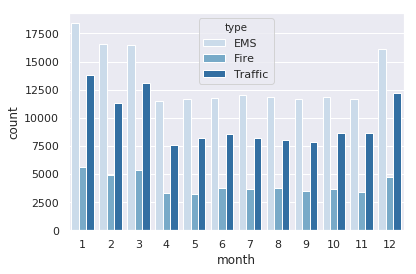

In [12]:
#To display the 911 calls for each month and display it for each type
sns.countplot(emergency['month'],hue = emergency['type'],palette="Blues")

#At the start of the year and also at the end of the year, the 911 calls
#are high (Jan,Feb,March and December)

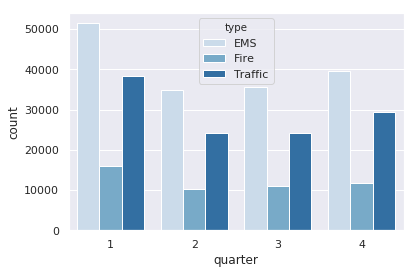

In [13]:
#To display the 911 calls for each quarter and display it for each type
sns.countplot(emergency['quarter'],hue = emergency['type'],palette="Blues")

#For quarter 1, the count of 911 calls for EMS type is highest
# For type - 'Fire', the calls are equally spread out for all the quarters

**Q6 - Histogram plot showing the variations in the emergencies with the change in hour of the day**

/opt/conda/lib/python3.6/site-packages/scipy/stats/stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


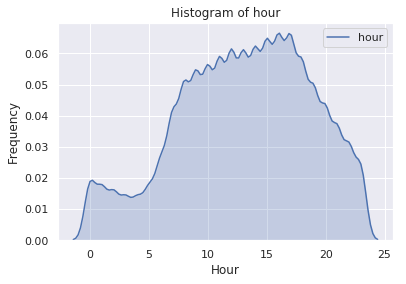

In [14]:
#Histogram plot with the variation in calls during the hours of the day
sns.kdeplot(emergency.hour,shade=True)
plt.title("Histogram of hour")
plt.xlabel("Hour")
plt.ylabel("Frequency")
plt.show()

#At around 4 PM, the number of calls have peaked and are lower during the
#early hours of the day(3-5 AM)

**Q7 - Scatter plot of the longitute and lattitude of the emergencies**

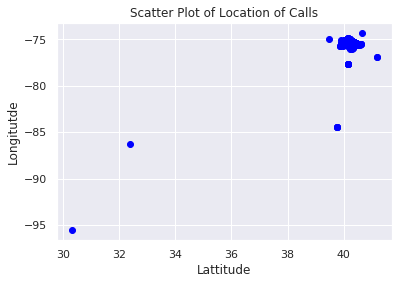

In [15]:
#scatter plot
plt.plot(emergency.lat, emergency.lng, 'o', color='blue');
plt.title("Scatter Plot of Location of Calls")
plt.xlabel("Lattitude")
plt.ylabel("Longitutde")
plt.show()
#seeing the scatter plot we can see that most of the emergencies 
#are from around lat = 40 and lon = -75 i.e. from a particular area
#upon checking the data - town 'LOWER MERION' is around the clustered (lat,Lon)

**Extract only the EMS type dataset and store the timestamp and title in a subset**

In [16]:
#create a subset of only the EMS type
ems = emergency[emergency['type']=='EMS']
#ems.reset_index(inplace=True)
ems_subset = ems[['timeStamp','title','e']]

**Do a pivot to display all the EMS types in columns and perform resampling in the time series data on week basis**

In [17]:
#merge the count of calls on the basis of week using resample.
#This can be done as this is a time series data

piv=pd.pivot_table(ems_subset, values='e', index=['timeStamp'], columns=['title'], aggfunc=np.sum)
piv1=piv.resample('W', how=[np.sum]).reset_index()  #'W' represents the week
piv1.head()

/opt/conda/lib/python3.6/site-packages/ipykernel_launcher.py:5: FutureWarning: how in .resample() is deprecated
the new syntax is .resample(...)..apply(<func>)
  """


,timeStamp,EMS: ABDOMINAL PAINS,EMS: ACTIVE SHOOTER,EMS: ALLERGIC REACTION,EMS: ALTERED MENTAL STATUS,EMS: AMPUTATION,EMS: ANIMAL BITE,EMS: APPLIANCE FIRE,EMS: ARMED SUBJECT,EMS: ASSAULT VICTIM,EMS: BACK PAINS/INJURY,EMS: BOMB DEVICE FOUND,EMS: BOMB THREAT,EMS: BUILDING FIRE,EMS: BURN VICTIM,EMS: CARBON MONOXIDE DETECTOR,EMS: CARDIAC ARREST,EMS: CARDIAC EMERGENCY,EMS: CHOKING,EMS: CVA/STROKE,EMS: DEBRIS/FLUIDS ON HIGHWAY,EMS: DEHYDRATION,EMS: DIABETIC EMERGENCY,EMS: DISABLED VEHICLE,EMS: DIZZINESS,EMS: DROWNING,EMS: ELECTRICAL FIRE OUTSIDE,EMS: ELECTROCUTION,EMS: EMS SPECIAL SERVICE,EMS: EYE INJURY,EMS: FALL VICTIM,EMS: FEVER,EMS: FIRE ALARM,EMS: FIRE INVESTIGATION,EMS: FIRE POLICE NEEDED,EMS: FIRE SPECIAL SERVICE,EMS: FRACTURE,EMS: GAS-ODOR/LEAK,EMS: GENERAL WEAKNESS,EMS: HAZARDOUS MATERIALS INCIDENT,EMS: HEAD INJURY,EMS: HEAT EXHAUSTION,EMS: HEMORRHAGING,EMS: HIT + RUN,EMS: INDUSTRIAL ACCIDENT,EMS: LACERATIONS,EMS: MATERNITY,EMS: MEDICAL ALERT ALARM,EMS: NAUSEA/VOMITING,EMS: OVERDOSE,EMS: PLANE CRASH,EMS: POISONING,EMS: RESCUE - ELEVATOR,EMS: RESCUE - GENERAL,EMS: RESCUE - TECHNICAL,EMS: RESCUE - WATER,EMS: RESPIRATORY EMERGENCY,EMS: S/B AT HELICOPTER LANDING,EMS: SEIZURES,EMS: SHOOTING,EMS: STABBING,EMS: STANDBY FOR ANOTHER CO,EMS: SUBJECT IN PAIN,EMS: SUICIDE THREAT,EMS: SUSPICIOUS,EMS: SYNCOPAL EPISODE,EMS: TRAIN CRASH,EMS: TRANSFERRED CALL,EMS: TRASH/DUMPSTER FIRE,EMS: UNCONSCIOUS SUBJECT,EMS: UNKNOWN MEDICAL EMERGENCY,EMS: UNKNOWN TYPE FIRE,EMS: UNRESPONSIVE SUBJECT,EMS: VEHICLE ACCIDENT,EMS: VEHICLE FIRE,EMS: WARRANT SERVICE,EMS: WOODS/FIELD FIRE
,,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum,sum
0,2015-12-13,18.0,0.0,8.0,15.0,0.0,0.0,1.0,0.0,11.0,7.0,0.0,0.0,1.0,1.0,1.0,0.0,65.0,4.0,17.0,0.0,2.0,9.0,0.0,13.0,0.0,0.0,0.0,2.0,0.0,66.0,7.0,0.0,0.0,0.0,1.0,6.0,0.0,20.0,0.0,39.0,0.0,17.0,0.0,0.0,6.0,2.0,15.0,12.0,15.0,0.0,0.0,0.0,2.0,0.0,0.0,60.0,0.0,15.0,0.0,0.0,0.0,30.0,0.0,0.0,27.0,0.0,0.0,0.0,18.0,24.0,0.0,17.0,48.0,0.0,1.0,0.0
1,2015-12-20,34.0,0.0,9.0,35.0,1.0,1.0,0.0,0.0,15.0,25.0,0.0,0.0,8.0,1.0,3.0,0.0,137.0,7.0,28.0,0.0,1.0,29.0,0.0,27.0,0.0,0.0,1.0,2.0,1.0,112.0,9.0,0.0,0.0,0.0,1.0,12.0,0.0,33.0,0.0,58.0,0.0,27.0,0.0,0.0,10.0,3.0,27.0,29.0,27.0,0.0,3.0,0.0,1.0,2.0,0.0,124.0,0.0,43.0,2.0,1.0,0.0,58.0,0.0,0.0,41.0,0.0,0.0,0.0,34.0,49.0,0.0,25.0,114.0,0.0,0.0,0.0
2,2015-12-27,47.0,0.0,11.0,34.0,0.0,2.0,1.0,0.0,15.0,16.0,0.0,0.0,3.0,3.0,2.0,0.0,133.0,7.0,27.0,0.0,2.0,30.0,0.0,17.0,0.0,0.0,0.0,5.0,1.0,136.0,9.0,1.0,0.0,0.0,1.0,14.0,0.0,41.0,1.0,56.0,0.0,35.0,0.0,0.0,8.0,6.0,28.0,27.0,33.0,0.0,1.0,1.0,0.0,0.0,0.0,168.0,0.0,50.0,1.0,4.0,0.0,53.0,0.0,0.0,49.0,0.0,0.0,0.0,23.0,42.0,0.0,30.0,141.0,3.0,0.0,0.0
3,2016-01-03,48.0,0.0,14.0,28.0,0.0,2.0,0.0,0.0,23.0,30.0,0.0,0.0,3.0,1.0,4.0,0.0,149.0,3.0,26.0,0.0,3.0,20.0,0.0,17.0,0.0,0.0,1.0,3.0,0.0,135.0,19.0,0.0,1.0,0.0,1.0,10.0,0.0,47.0,1.0,67.0,0.0,34.0,0.0,0.0,9.0,4.0,32.0,22.0,31.0,0.0,0.0,0.0,1.0,0.0,0.0,136.0,0.0,46.0,0.0,3.0,0.0,81.0,0.0,0.0,47.0,0.0,0.0,0.0,26.0,39.0,1.0,36.0,92.0,1.0,0.0,0.0
4,2016-01-10,43.0,0.0,8.0,46.0,0.0,2.0,1.0,0.0,19.0,23.0,0.0,0.0,7.0,0.0,4.0,0.0,116.0,4.0,43.0,0.0,5.0,24.0,0.0,18.0,0.0,0.0,0.0,4.0,1.0,167.0,14.0,1.0,0.0,0.0,0.0,18.0,1.0,45.0,0.0,76.0,0.0,41.0,0.0,0.0,11.0,2.0,36.0,22.0,28.0,0.0,1.0,0.0,2.0,0.0,0.0,160.0,0.0,50.0,4.0,2.0,0.0,74.0,0.0,0.0,45.0,0.0,0.0,0.0,23.0,57.0,0.0,38.0,102.0,1.0,0.0,0.0


**Q8 - Plot the line graph showing the timestamp for the Assault Victims **

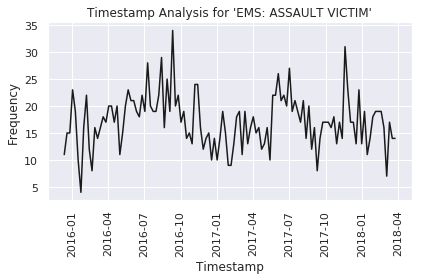

In [18]:
#Plot for 'EMS: ASSAULT VICTIM' on the basis of the timestamp

plt.xticks(rotation=90)
plt.plot_date(piv1['timeStamp'], piv1['EMS: ASSAULT VICTIM'],'k')
plt.title("Timestamp Analysis for 'EMS: ASSAULT VICTIM'")
plt.xlabel("Timestamp")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#Seeing the plot we can observe that during october of 2016, the calls for
#'EMS: ASSAULT VICTIM' were highest
#Also seeing the trend, the calls for 'EMS: ASSAULT VICTIM' increased
#as the year 2016 progressed. But it didn't follow the same trend in 2017
#and fluctuated throughout the year 2017

**Q9 - Compare the Assault victim and the Altered Mental Status emergencies week wise**

[]

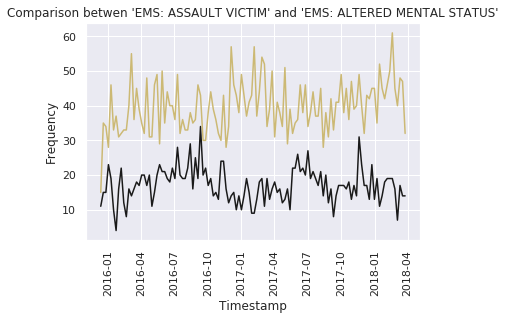

In [19]:
#comparison betwen 'EMS: ASSAULT VICTIM' and 'EMS: ALTERED MENTAL STATUS'

plt.subplot()
plt.xticks(rotation=90)
plt.plot_date(piv1['timeStamp'], piv1['EMS: ASSAULT VICTIM'],'k')
#plt.plot_date(piv1['timeStamp'], piv1['EMS: ASSAULT VICTIM'],'r.')


plt.plot_date(piv1['timeStamp'], piv1['EMS: ALTERED MENTAL STATUS'],'y')
#plt.plot_date(piv1['timeStamp'], piv1['EMS: ALTERED MENTAL STATUS'],'b.')
#plt.set_title("EMS: ASSAULT VICTIM vs  EMS: ALTERED MENTAL STATUS")

plt.title("Comparison betwen 'EMS: ASSAULT VICTIM' and 'EMS: ALTERED MENTAL STATUS'")
plt.xlabel("Timestamp")
plt.ylabel("Frequency")
plt.plot()

#from the plot we can observe that 'EMS: ALTERED MENTAL STATUS' has higher
#calls compared to the 'EMS: ASSAULT VICTIM'.
#Seeing the trend of 'EMS: ALTERED MENTAL STATUS', we can observe that there
#is no specific pattern to it.
#Only during the end of 2016, 'EMS: ASSAULT VICTIM' peaks and crosses the
#count of 'EMS: ALTERED MENTAL STATUS'

**Q10 - Top 10 towns with the 911 emergency calls**

                      e
twp                    
LOWER MERION      28073
ABINGTON          20206
NORRISTOWN        18433
UPPER MERION      17276
CHELTENHAM        15026
POTTSTOWN         13503
UPPER MORELAND    11256
LOWER PROVIDENCE  10791
PLYMOUTH           9749
HORSHAM            9215


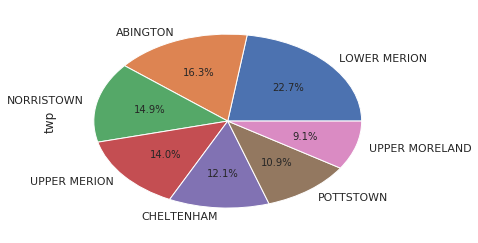

In [20]:
#Top 10 towns with the 911 emergecny calls
town = emergency.pivot_table(values = 'e',index=['twp'],aggfunc='count')
print(town.sort_values('e',ascending=False).head(10))
emergency.groupby(['twp'])['twp'].size().sort_values(ascending=False).head(7).plot(kind='pie',autopct='%1.1f%%')

#Seeing the table and pie-chart,we can observe that 'LOWER MERION' made
#the highest 911 calls

**Q11 - Drill down for town = 'LOWER MERION' and observe the monthwise 911 calls**

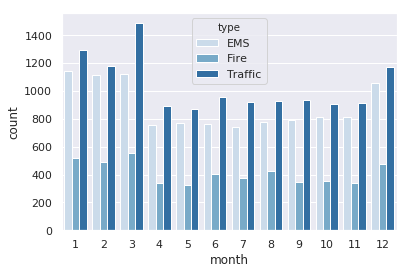

In [21]:
#As town 'LOWER MERION' has the highest 911 calls, we drill down to
#that data and check the data

twp = emergency[emergency['twp']=='LOWER MERION']

#countplot month wise for town = 'LOWER MERION'
sns.countplot(twp['month'],hue = twp['type'],palette="Blues")

#Seeing the countplot for the town = 'LOWER MERION', we can observe the
#same trend as was observed for the entire emergency data.

**Q12 - Comparing the data with town = 'LOWER MERION' and the drilled down date of LOWER MERION town with type as 'EMS'**

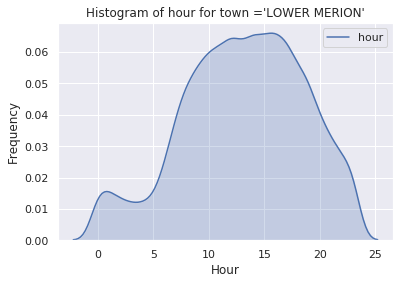

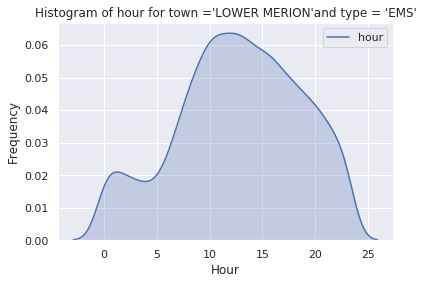

In [22]:
plt.figure(1)
sns.kdeplot(twp.hour,shade=True)
plt.title("Histogram of hour for town ='LOWER MERION'")
plt.xlabel("Hour")
plt.ylabel("Frequency")
plt.show()

plt.figure(2)
twp_EMS = twp[twp['type']=='EMS']
sns.kdeplot(twp_EMS.hour,shade=True)
plt.title("Histogram of hour for town ='LOWER MERION'and type = 'EMS'")
plt.xlabel("Hour")
plt.ylabel("Frequency")
plt.show()

#Here plot 1 is for town = 'LOWER MERION' and plot is for the drilled
#down data of plot 1 with type as 'EMS'

#Seeing both the plots we can observe that with further drill down of data
#of 'LOWER MERION' town, there is a shift in the peak in the hour of the
#day with highest 911 calls.
#For town = 'LOWER MERION', at around 3 PM the 911 calls peaked
#while only checking for EMS type calls, the peak shifts at around 12 PM

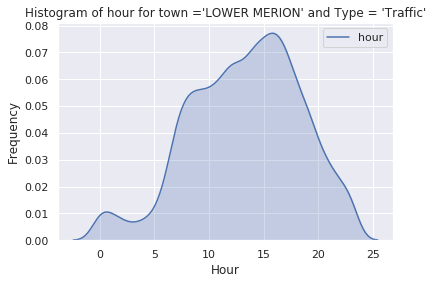

In [23]:
twp_Traffic = twp[twp['type']=='Traffic']
sns.kdeplot(twp_Traffic.hour,shade=True)
plt.title("Histogram of hour for town ='LOWER MERION' and Type = 'Traffic'")
plt.xlabel("Hour")
plt.ylabel("Frequency")
plt.show()
#on the other hand for type as Traffic, the peak shifts towards right
#at around 4 PM

#This explains that for different types of 911 calls, the peak hours vary